# BCS quantum simulation: paper reproduction

Notebook reprodutível para acompanhar o manuscrito `papers/bcs_quantum_simulation.md`.

Ele assume que os experimentos já foram executados e que as tabelas/figuras existem em `results/`. A última seção traz os comandos para regenerar tudo.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'results').exists() else cwd.parent
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'

pd.set_option('display.max_columns', 80)
pd.set_option('display.precision', 6)

## Parâmetros principais

O caso padrão usado no paper é o Hamiltoniano BCS reduzido com quatro modos de pares.

In [2]:
params = {
    'xi': [-1.0, -0.35, 0.35, 1.0],
    'g': 0.8,
    'occupied': [0, 1],
    'time': 2.5,
    'final_time_observables': 6.0,
    'trotter_steps': 8,
    'trotter_order': 2,
}
params

{'xi': [-1.0, -0.35, 0.35, 1.0],
 'g': 0.8,
 'occupied': [0, 1],
 'time': 2.5,
 'final_time_observables': 6.0,
 'trotter_steps': 8,
 'trotter_order': 2}

## Funções auxiliares

In [3]:
def read_table(name):
    path = TABLES / name
    if not path.exists():
        raise FileNotFoundError(f'Missing table: {path}')
    return pd.read_csv(path)

def show_figure(name, width=850):
    path = FIGURES / name
    if not path.exists():
        raise FileNotFoundError(f'Missing figure: {path}')
    display(Image(filename=str(path), width=width))

def section(title):
    display(Markdown(f'## {title}'))

## Dinâmica BCS e erro de Trotter

In [4]:
trotter = read_table('bcs_dynamics_trotter.csv')
display(trotter)
best = trotter.sort_values('fidelity', ascending=False).iloc[0]
best[['time', 'steps', 'order', 'fidelity', 'state_error', 'exact_gap_proxy', 'trotter_gap_proxy']]

,time,steps,order,fidelity,state_error,exact_energy,trotter_energy,exact_pair_number,trotter_pair_number,exact_condensate_eigenvalue,trotter_condensate_eigenvalue,exact_gap_proxy,trotter_gap_proxy
0,2.5,1.0,1.0,0.016402,1.459181,2.7,-2.723483,2.0,2.0,1.008406,1.036248,0.803355,0.814370
1,2.5,2.0,1.0,0.422325,1.720592,2.7,0.591860,2.0,2.0,1.008406,1.181097,0.803355,0.869426
2,2.5,4.0,1.0,0.331926,0.964730,2.7,1.138241,2.0,2.0,1.008406,0.941494,0.803355,0.776245
3,2.5,8.0,1.0,0.905103,0.313054,2.7,2.725392,2.0,2.0,1.008406,1.014045,0.803355,0.805599
4,2.5,16.0,1.0,0.983735,0.129330,2.7,2.758153,2.0,2.0,1.008406,1.009876,0.803355,0.803941
5,2.5,32.0,1.0,0.996618,0.061080,2.7,2.736274,2.0,2.0,1.008406,1.008760,0.803355,0.803496
6,2.5,64.0,1.0,0.999226,0.030118,2.7,2.719874,2.0,2.0,1.008406,1.008493,0.803355,0.803390
7,2.5,128.0,1.0,0.999814,0.015015,2.7,2.710382,2.0,2.0,1.008406,1.008428,0.803355,0.803364
8,2.5,256.0,1.0,0.999955,0.007505,2.7,2.705305,2.0,2.0,1.008406,1.008411,0.803355,0.803358
9,2.5,1.0,2.0,0.684071,1.233649,2.7,2.154363,2.0,2.0,1.008406,0.999156,0.803355,0.799662


time                   2.500000
steps                256.000000
order                  2.000000
fidelity               1.000000
state_error            0.000104
exact_gap_proxy        0.803355
trotter_gap_proxy      0.803360
Name: 17, dtype: float64

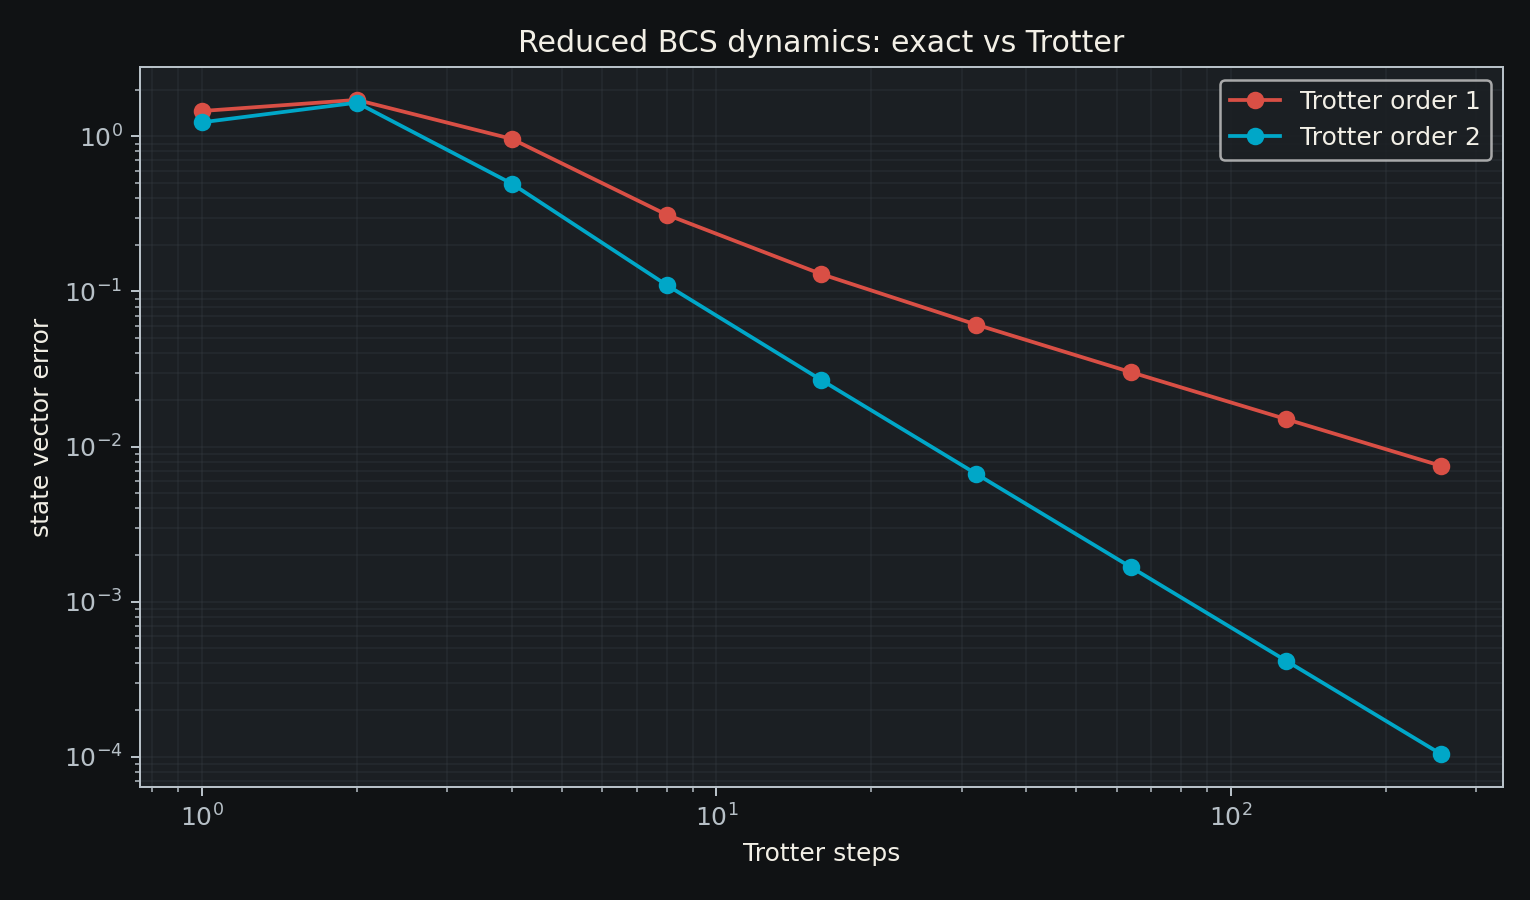

In [5]:
show_figure('bcs_trotter_error.png')

## Observáveis físicos para o paper

In [6]:
obs = read_table('bcs_paper_observables.csv')
final_obs = obs.iloc[-1]
final_obs[['time', 'fidelity', 'state_error', 'exact_pair_number', 'trotter_pair_number', 'exact_gap_proxy', 'trotter_gap_proxy']]

time                   6.000000
fidelity               1.000000
state_error            0.001410
exact_pair_number      2.000000
trotter_pair_number    2.000000
exact_gap_proxy        0.826271
trotter_gap_proxy      0.826182
Name: 80, dtype: float64

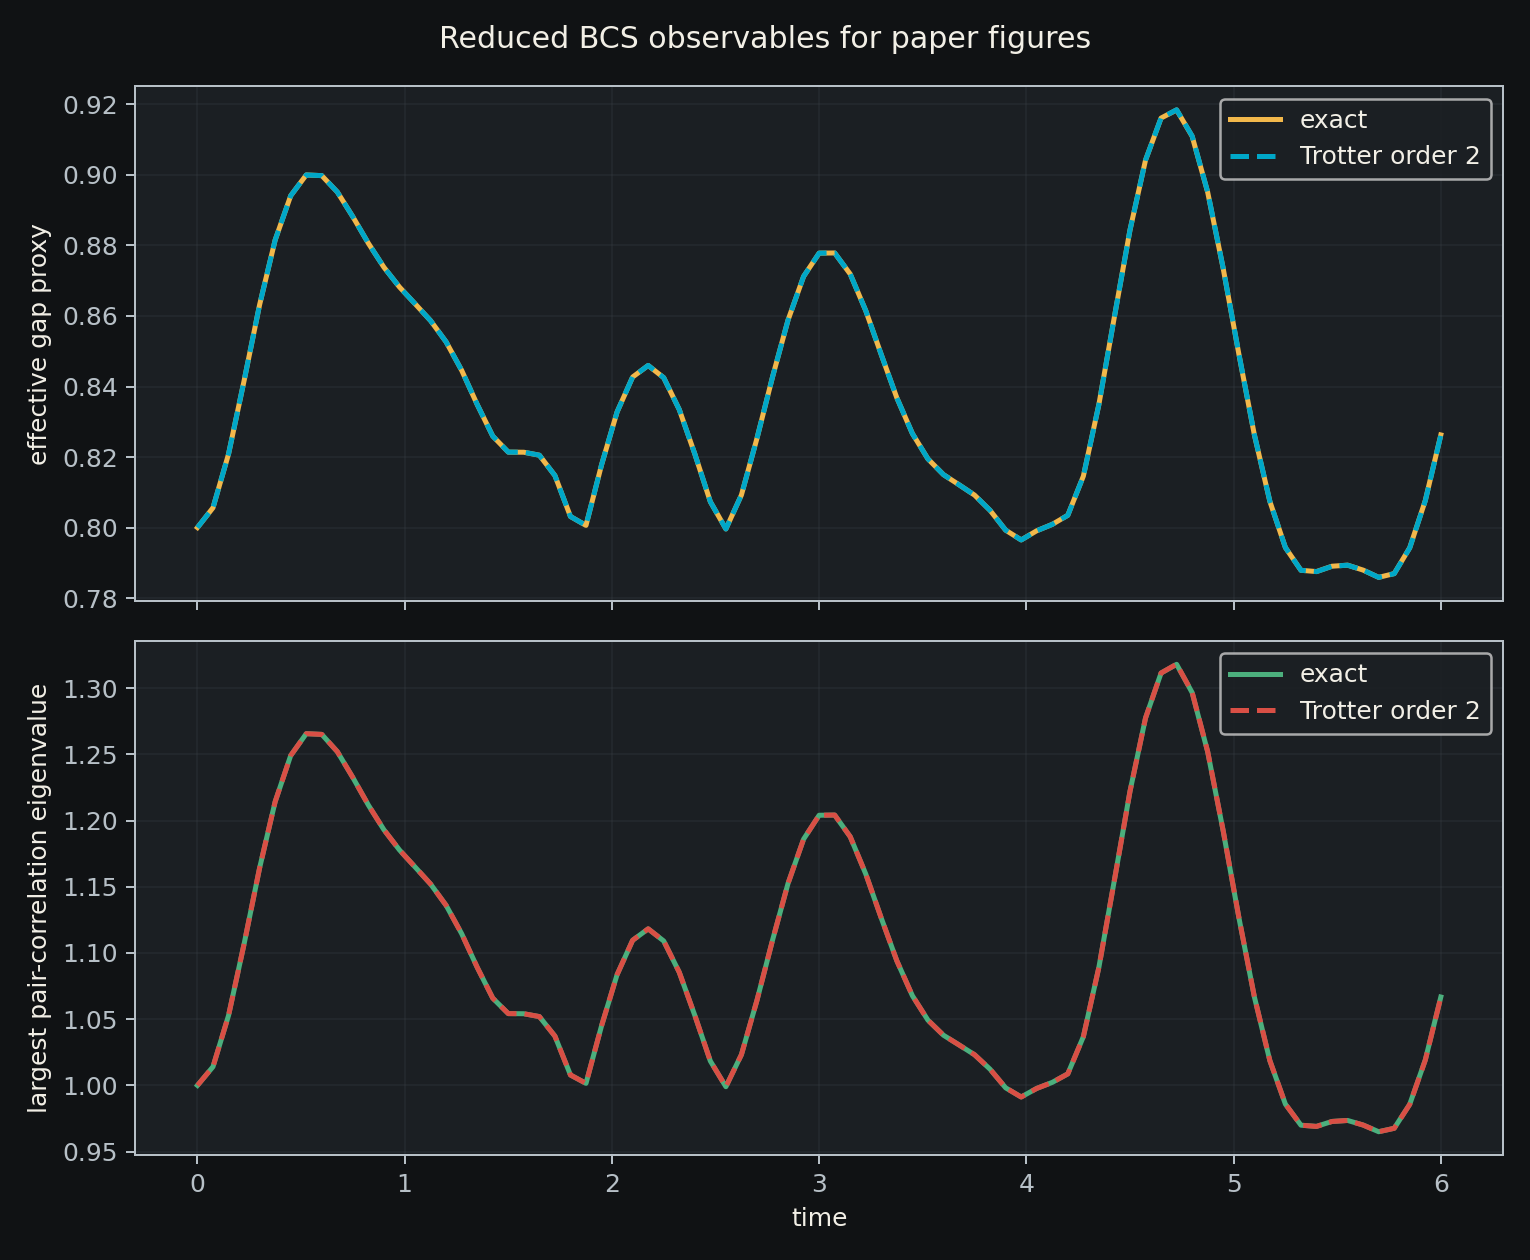

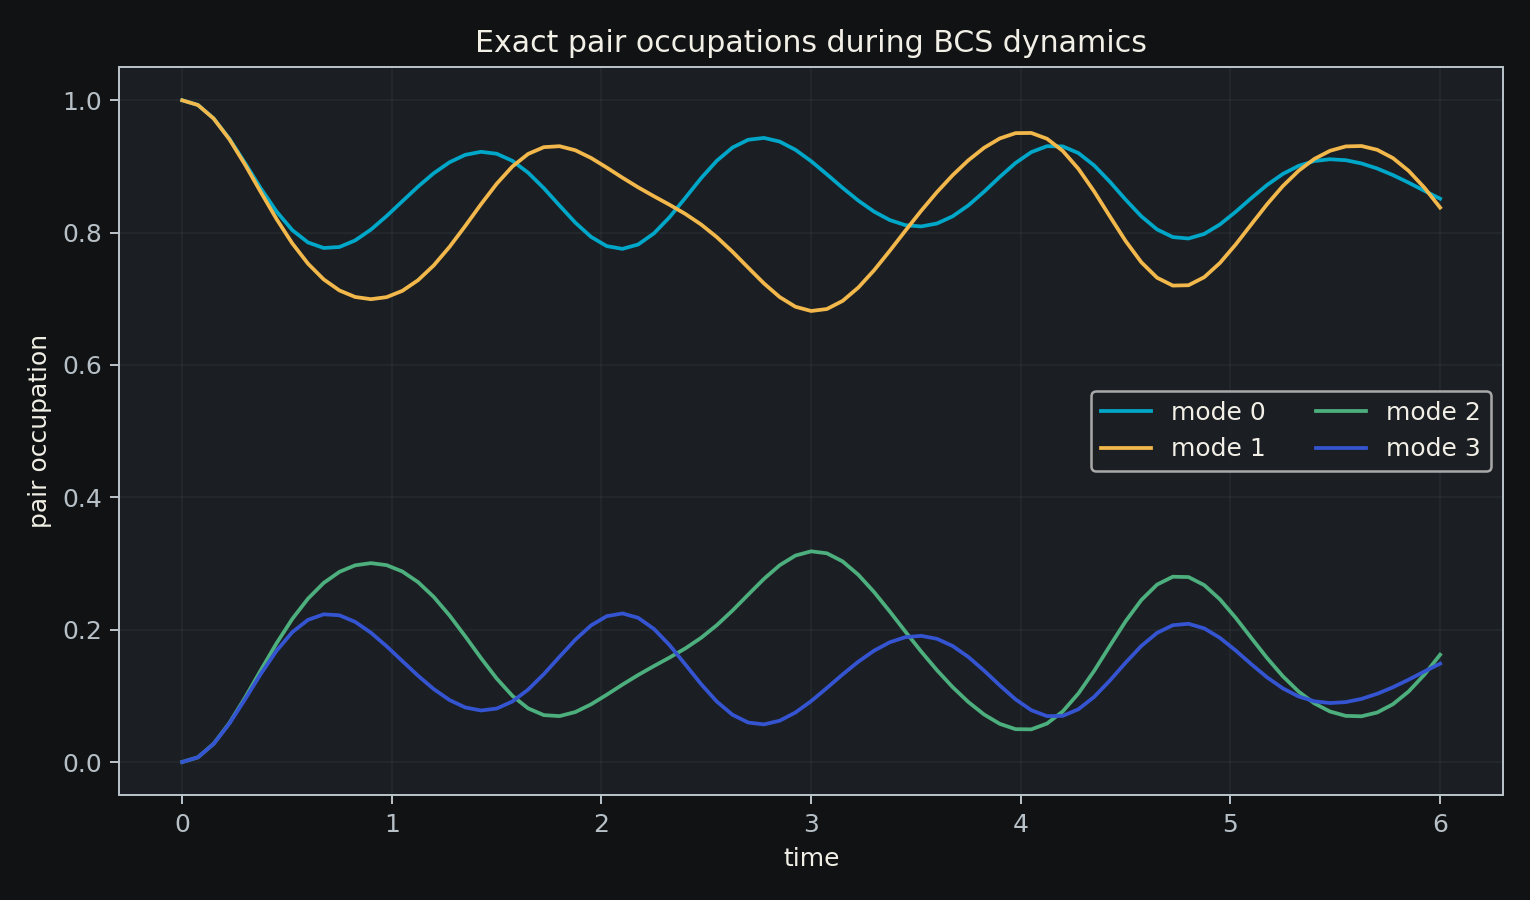

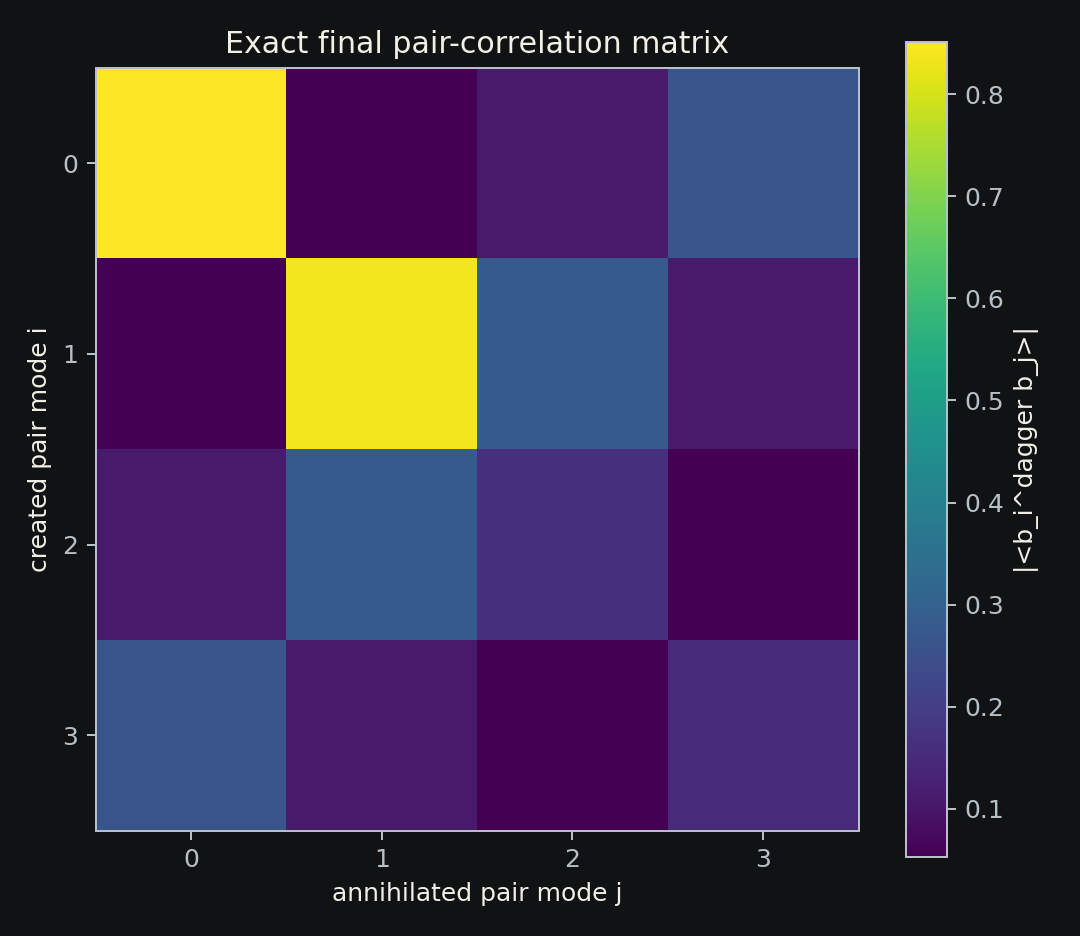

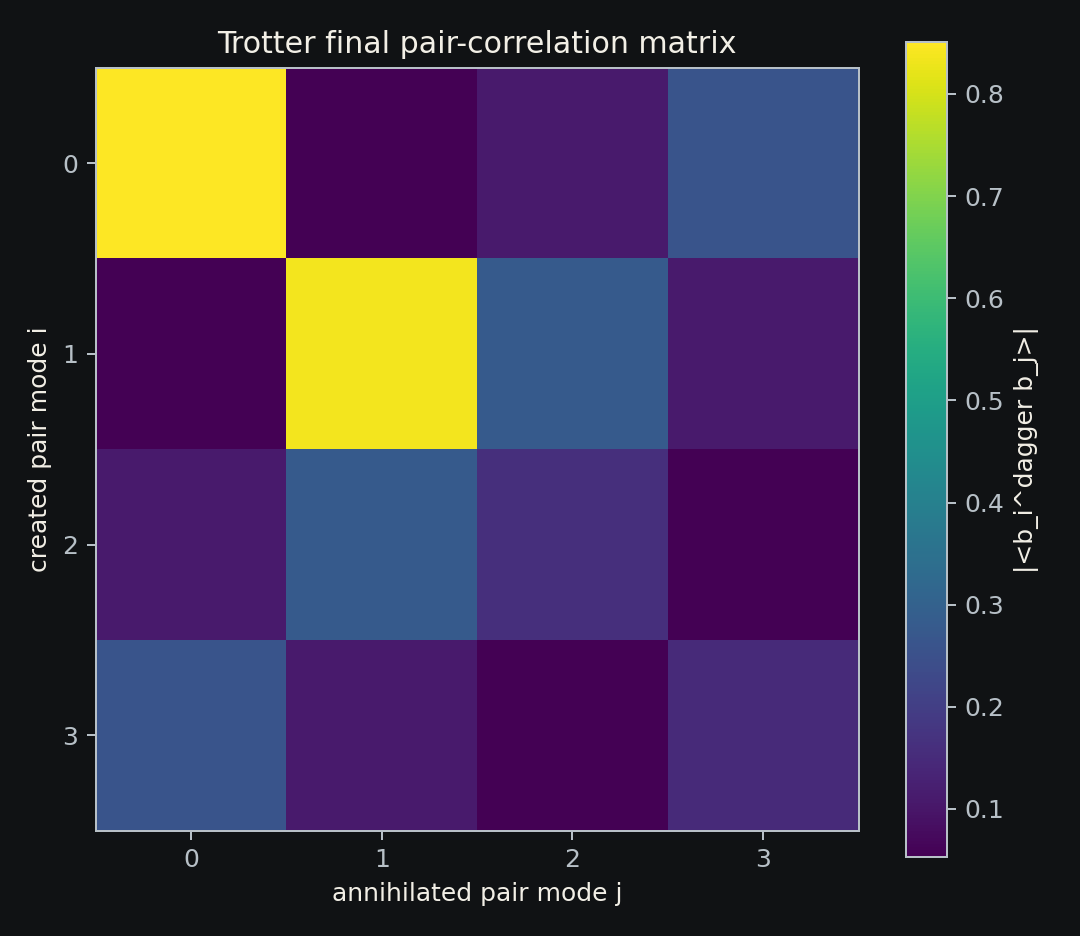

In [7]:
for fig in [
    'bcs_gap_condensate_time.png',
    'bcs_pair_occupations_time.png',
    'bcs_pair_correlation_exact_final.png',
    'bcs_pair_correlation_trotter_final.png',
]:
    show_figure(fig, width=760)

## Green normal, Gor'kov anômalo e matriz Nambu

In [8]:
green_spec = read_table('bcs_pair_green_spectral_density.csv')
gorkov_spec = read_table('bcs_gorkov_anomalous_spectrum.csv')
nambu_spec = read_table('bcs_gorkov_nambu_spectral_trace.csv')

summary_spectral = pd.DataFrame([
    {'channel': 'normal G', **green_spec.sort_values('spectral_weight', ascending=False).iloc[0][['omega', 'spectral_weight']].to_dict()},
    {'channel': 'anomalous F', **gorkov_spec.sort_values('spectral_weight', ascending=False).iloc[0][['omega', 'spectral_weight']].to_dict()},
    {'channel': 'Nambu trace', **nambu_spec.sort_values('spectral_weight', ascending=False).iloc[0][['omega', 'spectral_weight']].to_dict()},
])
summary_spectral

,channel,omega,spectral_weight
0,normal G,-1.044297,0.040784
1,anomalous F,3.132890,0.232452
2,Nambu trace,-2.436692,0.673764


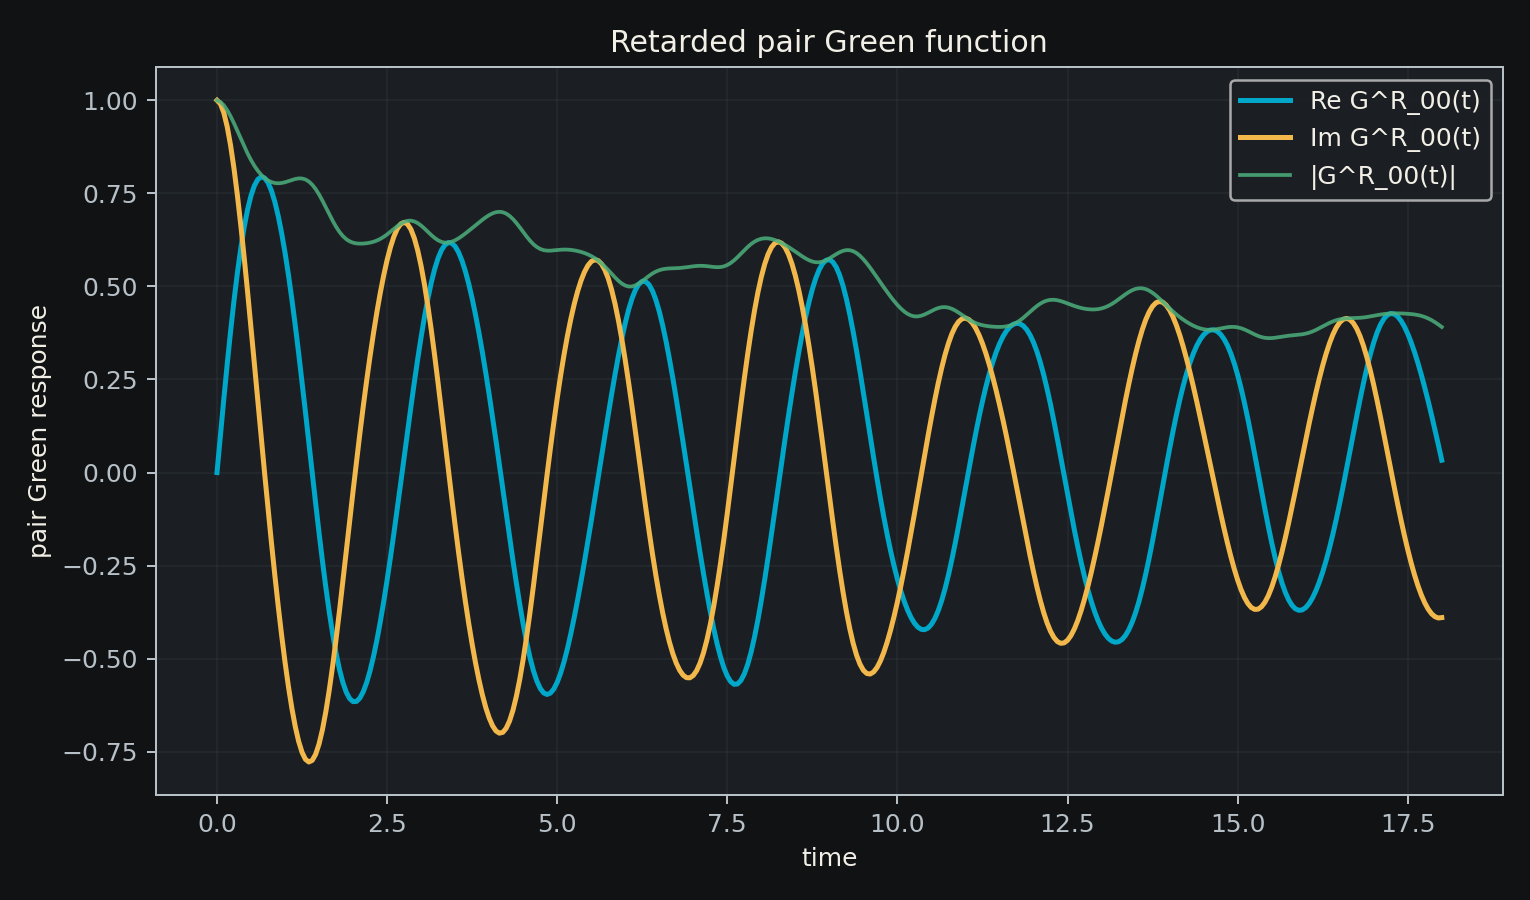

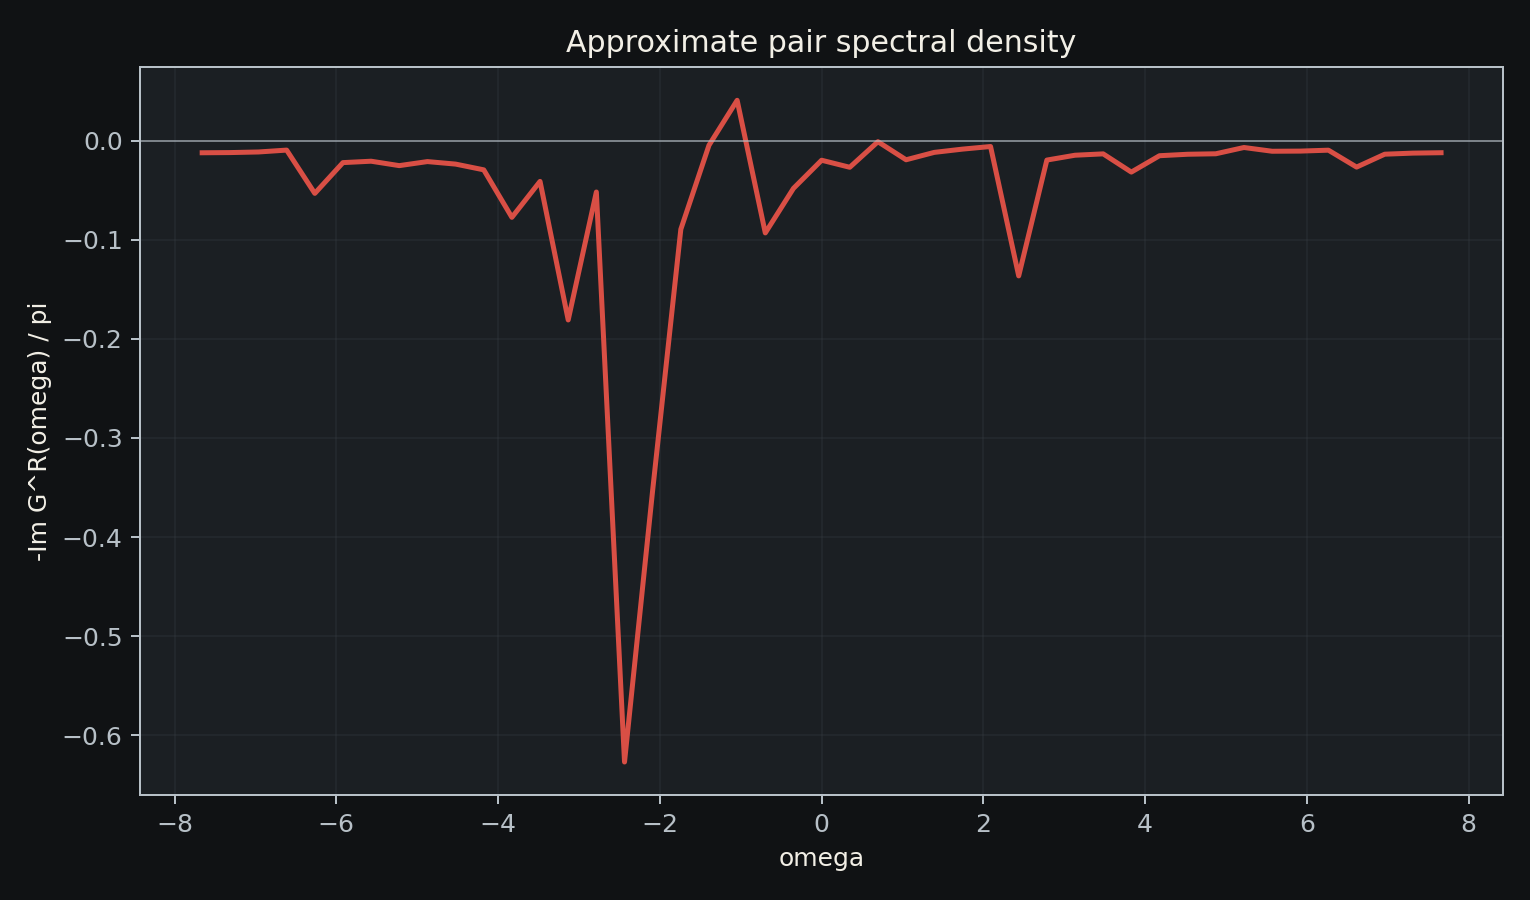

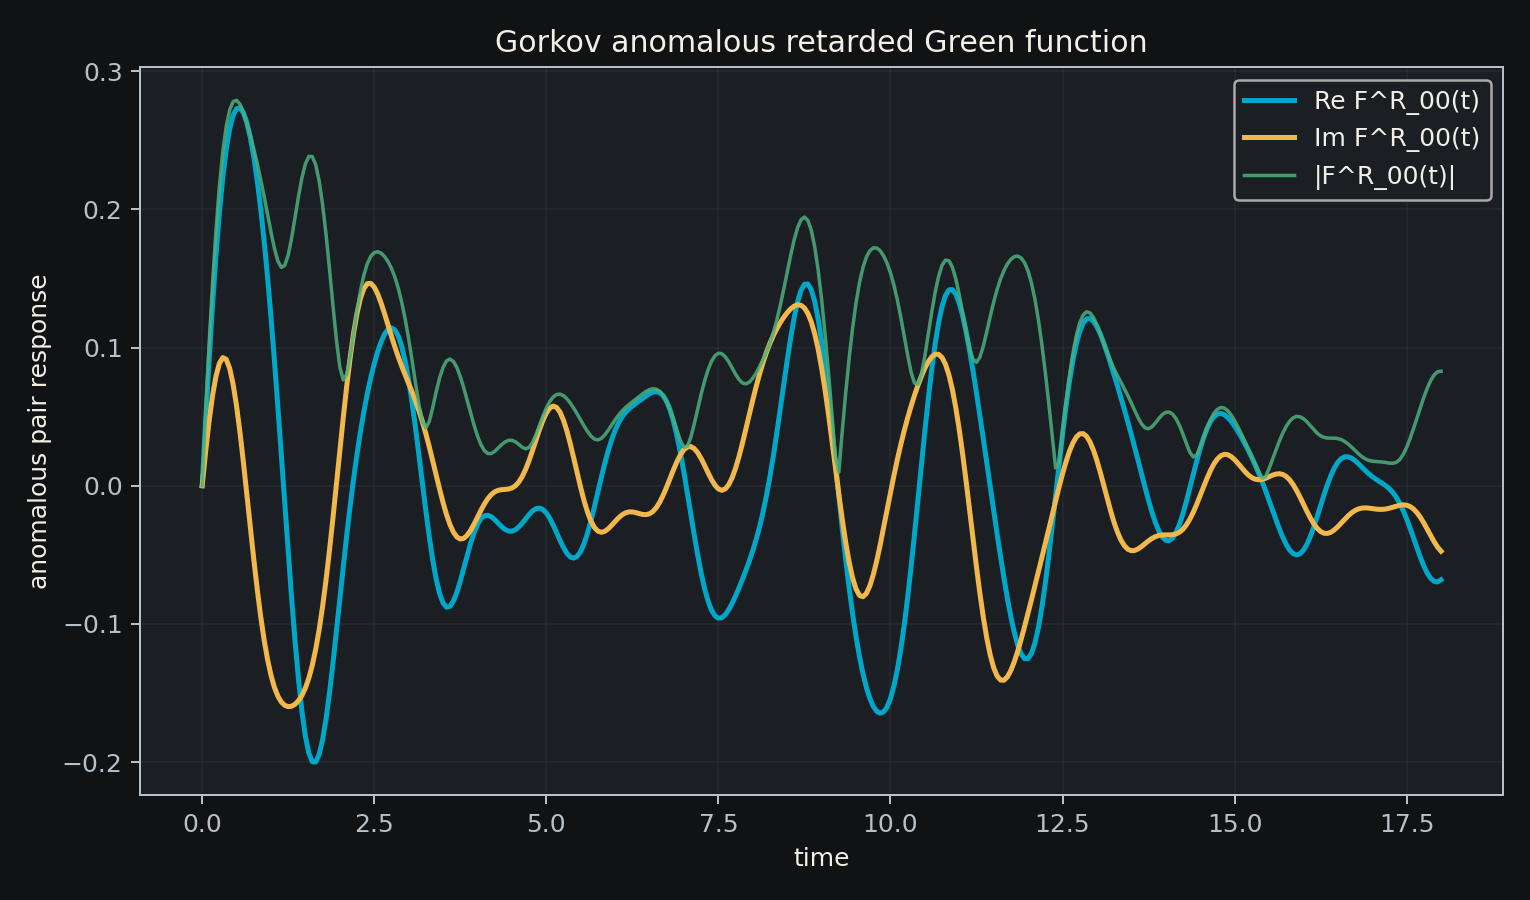

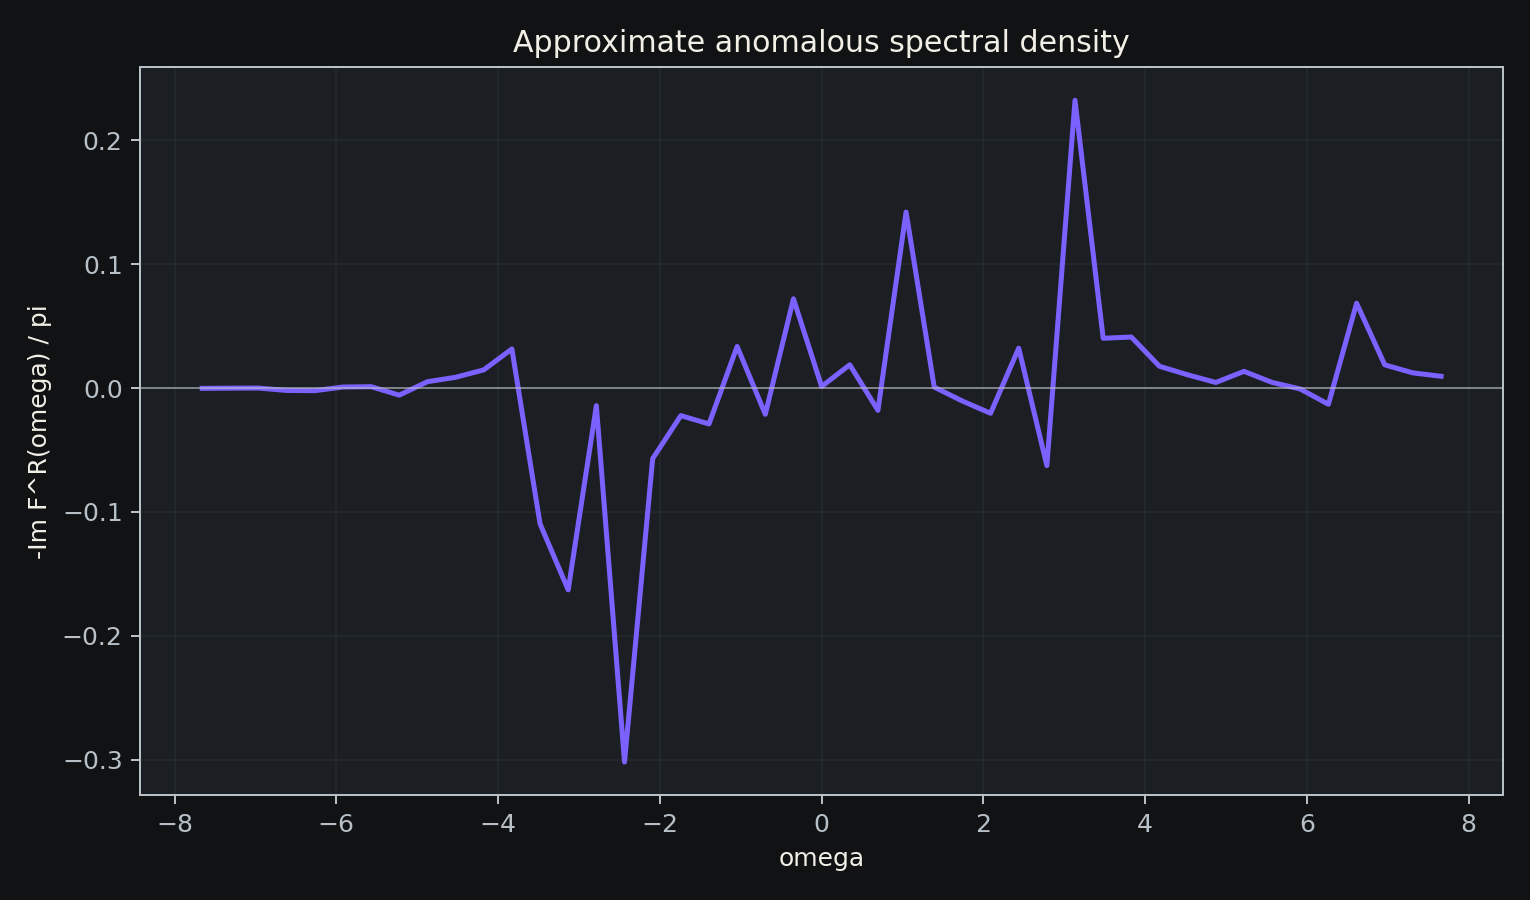

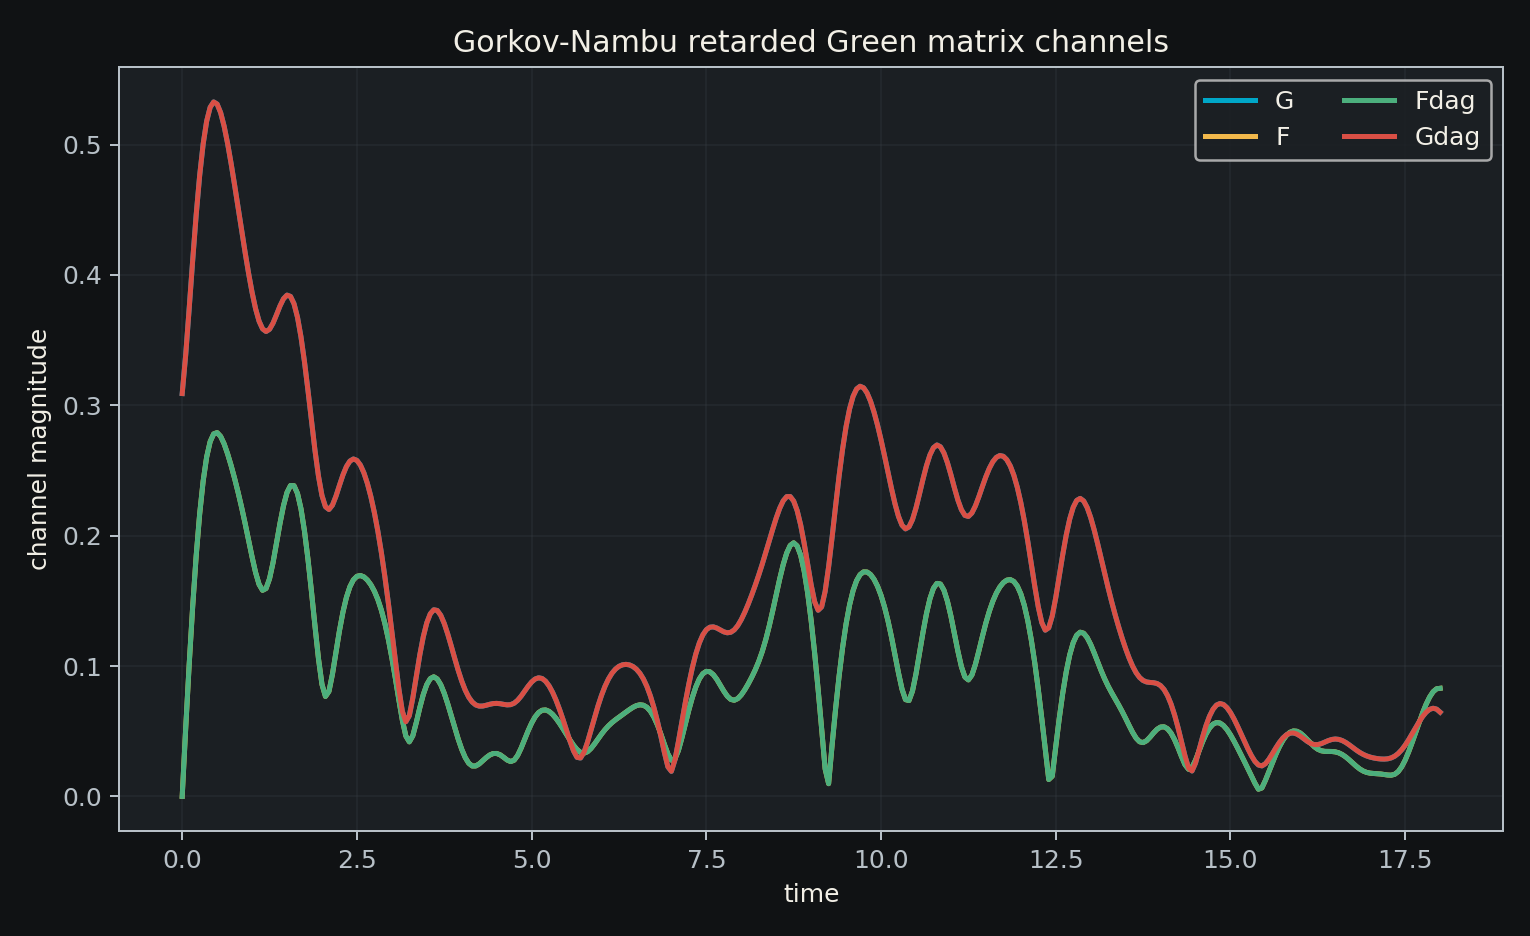

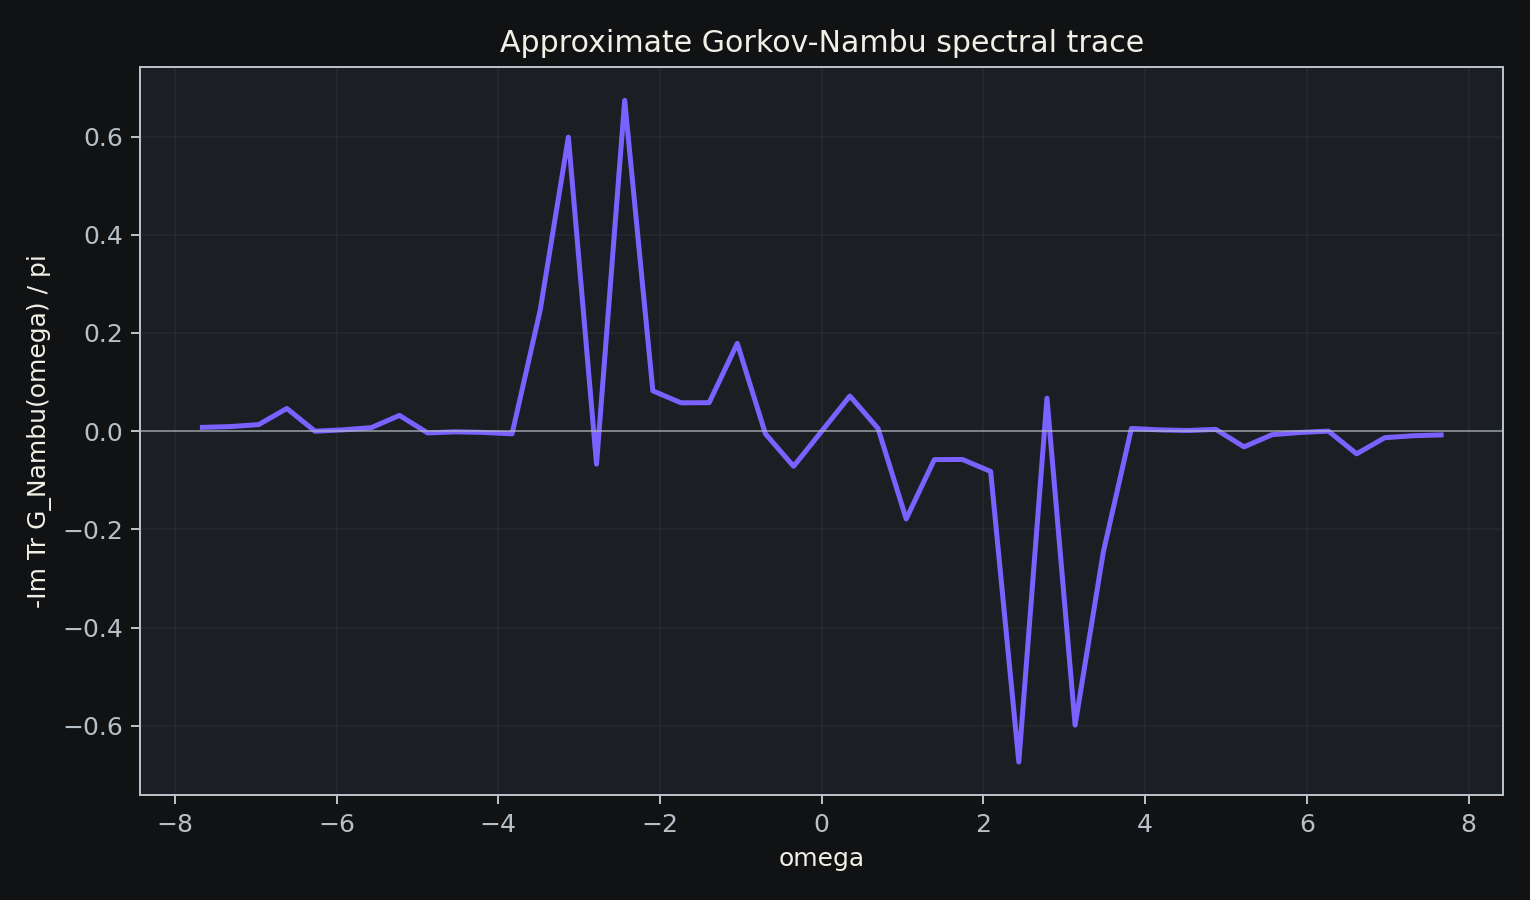

In [9]:
for fig in [
    'bcs_pair_green_time.png',
    'bcs_pair_green_spectrum.png',
    'bcs_gorkov_anomalous_time.png',
    'bcs_gorkov_anomalous_spectrum.png',
    'bcs_gorkov_nambu_channels.png',
    'bcs_gorkov_nambu_spectral_trace.png',
]:
    show_figure(fig, width=820)

## Qiskit shots, energia por Pauli e mitigação

In [10]:
shots = read_table('bcs_qiskit_shots_noise.csv')
energy = read_table('bcs_qiskit_energy_shots.csv')
mitigation = read_table('bcs_qiskit_error_mitigation.csv')

display(shots[['mode', 'shots', 'total_pair_number', 'total_pair_error']])
display(energy[['mode', 'shots', 'exact_energy', 'statevector_energy', 'energy', 'abs_error_vs_statevector']])
display(mitigation[['mode', 'noise_scale', 'energy', 'abs_error_vs_statevector', 'noise_slope', 'fit_rmse']])

,mode,shots,total_pair_number,total_pair_error
0,ideal_shots,1024.0,2.000000,3.330669e-14
1,noisy_shots,1024.0,1.950195,4.980469e-02
2,ideal_shots,4096.0,2.000000,3.330669e-14
3,noisy_shots,4096.0,1.996338,3.662109e-03
4,ideal_shots,8192.0,2.000000,3.330669e-14
5,noisy_shots,8192.0,1.979980,2.001953e-02
6,ideal_shots,16384.0,2.000000,3.330669e-14
7,noisy_shots,16384.0,1.995544,4.455566e-03
8,ideal_shots,32768.0,2.000000,3.330669e-14
9,noisy_shots,32768.0,1.989685,1.031494e-02


,mode,shots,exact_energy,statevector_energy,energy,abs_error_vs_statevector
0,ideal_shots,1024.0,2.7,2.61166,2.625391,0.013731
1,noisy_shots,1024.0,2.7,2.61166,0.125879,2.485781
2,ideal_shots,4096.0,2.7,2.61166,2.652319,0.040659
3,noisy_shots,4096.0,2.7,2.61166,0.244165,2.367495
4,ideal_shots,8192.0,2.7,2.61166,2.605103,0.006558
5,noisy_shots,8192.0,2.7,2.61166,0.210583,2.401077
6,ideal_shots,16384.0,2.7,2.61166,2.607983,0.003677
7,noisy_shots,16384.0,2.7,2.61166,0.202246,2.409414
8,ideal_shots,32768.0,2.7,2.61166,2.611313,0.000347
9,noisy_shots,32768.0,2.7,2.61166,0.214069,2.397592


,mode,noise_scale,energy,abs_error_vs_statevector,noise_slope,fit_rmse
0,scaled_noise,0.25,2.219580,0.392080,NaN,NaN
1,scaled_noise,0.50,1.915979,0.695681,NaN,NaN
2,scaled_noise,0.75,1.632208,0.979452,NaN,NaN
3,scaled_noise,1.00,1.404230,1.207430,NaN,NaN
4,linear_zne,0.00,2.475455,0.136205,-1.091929,0.019328


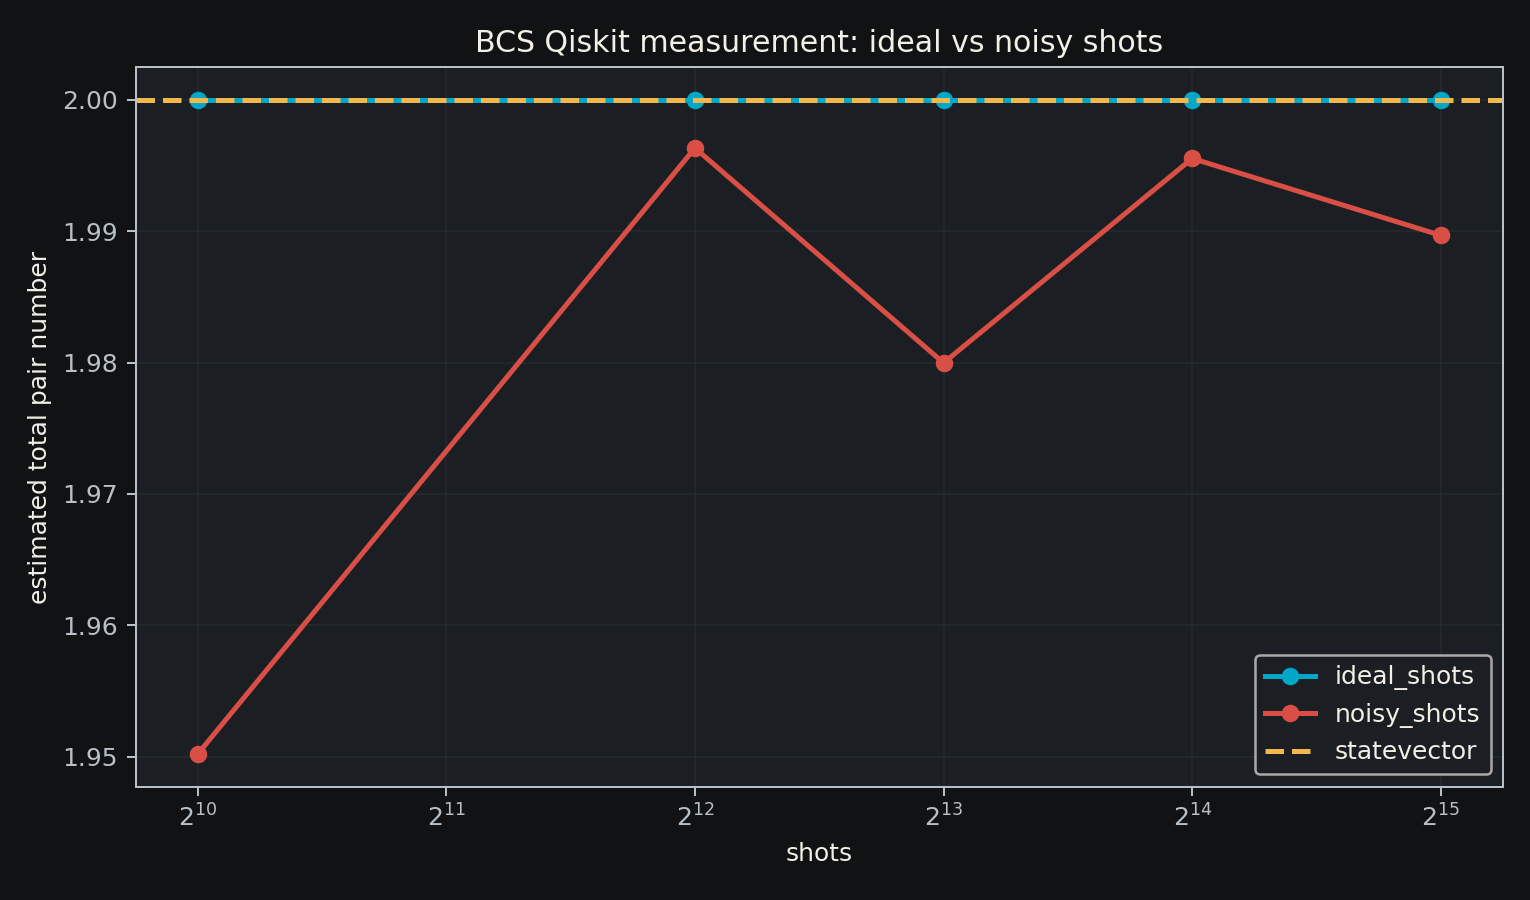

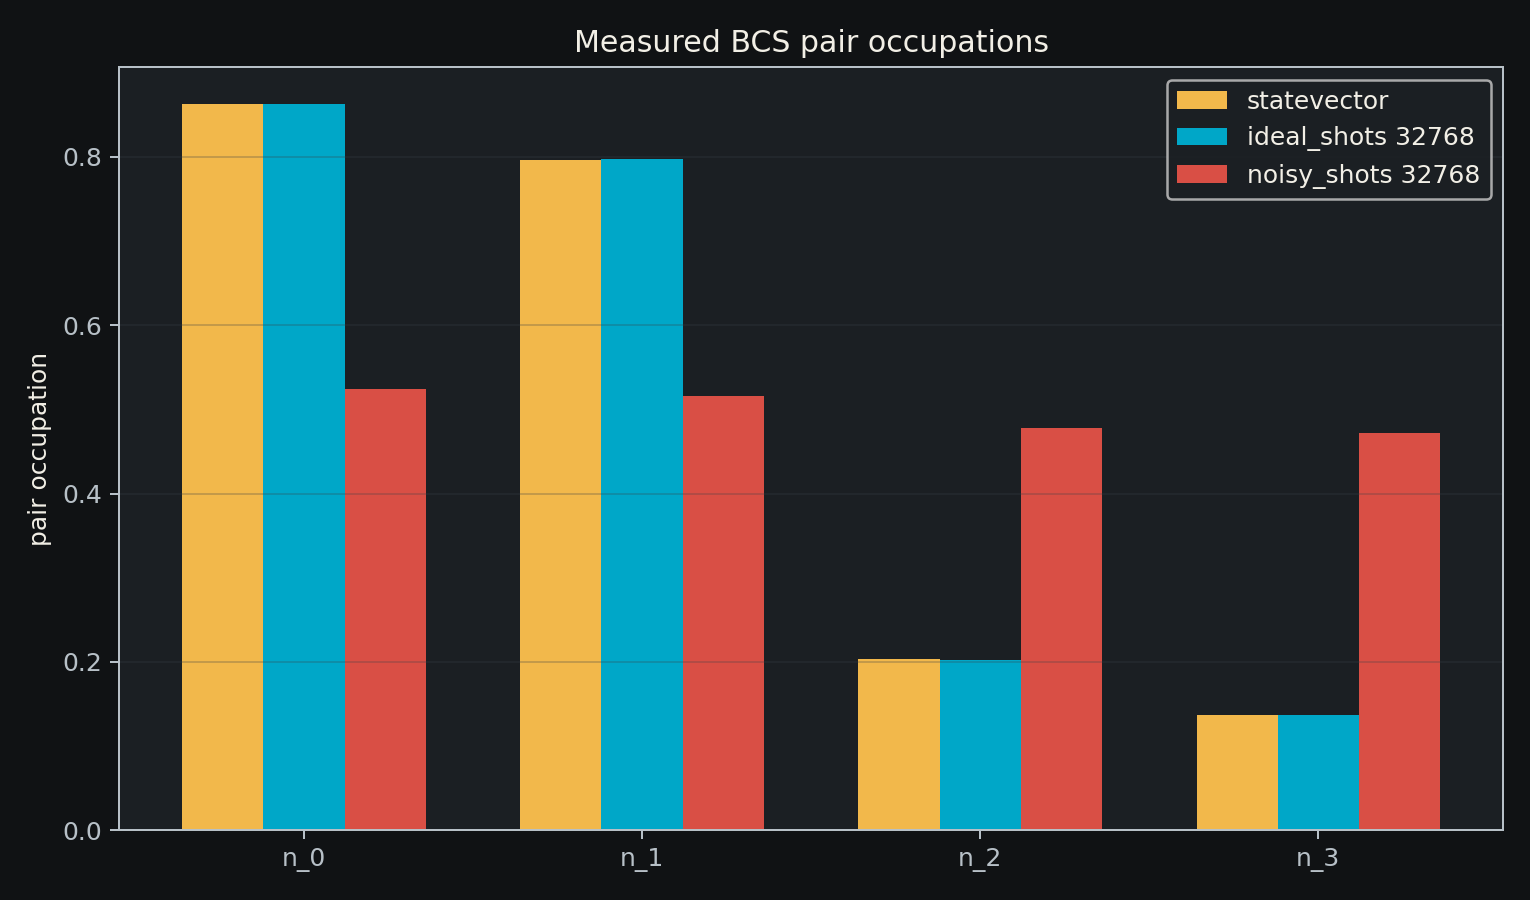

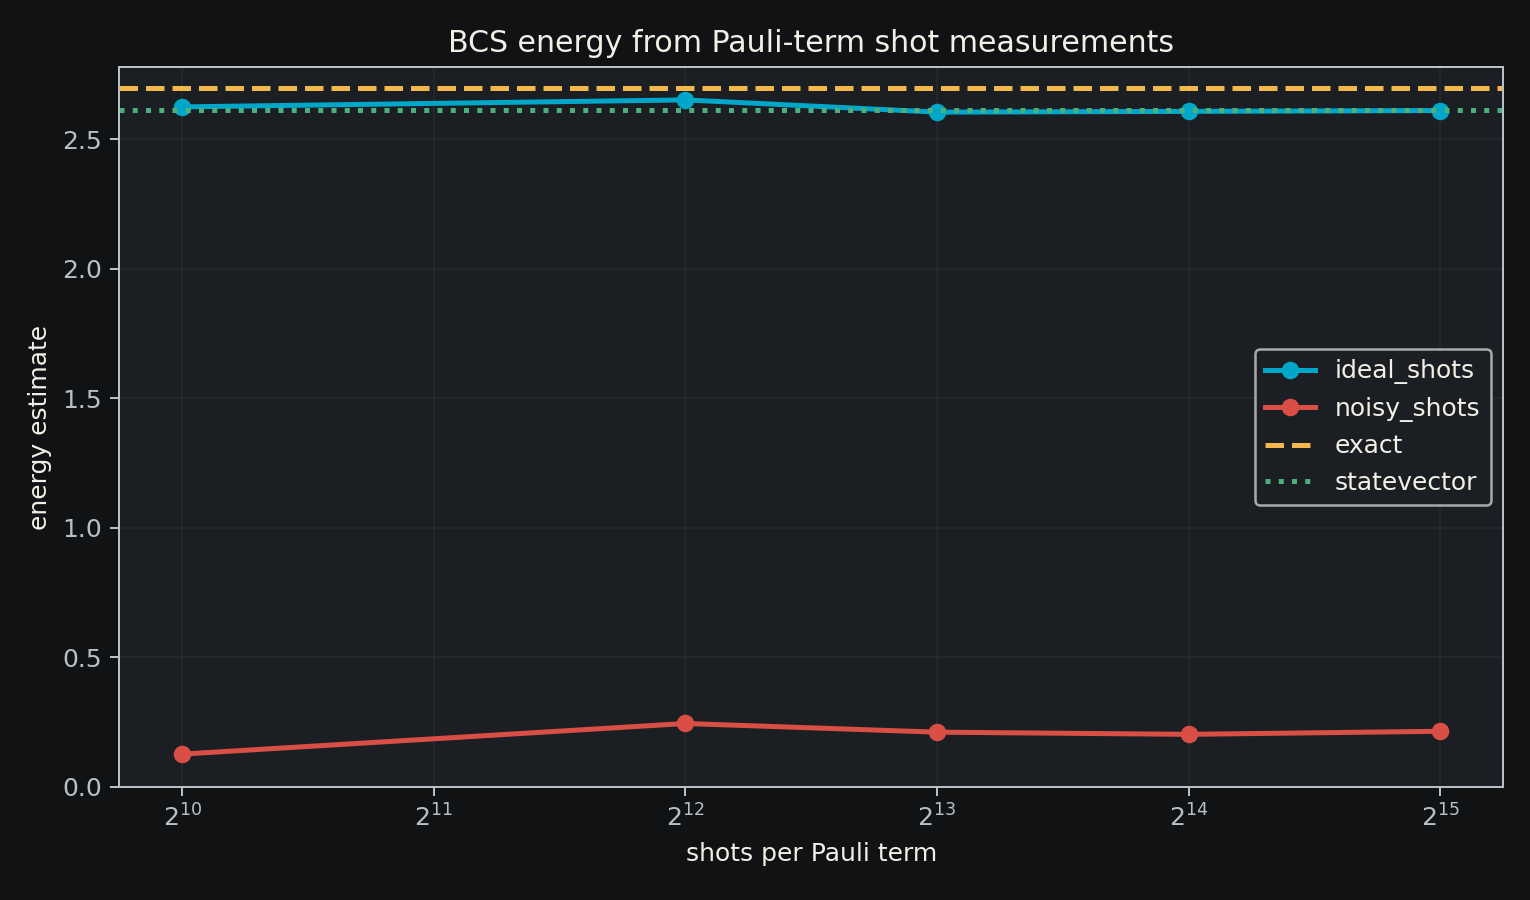

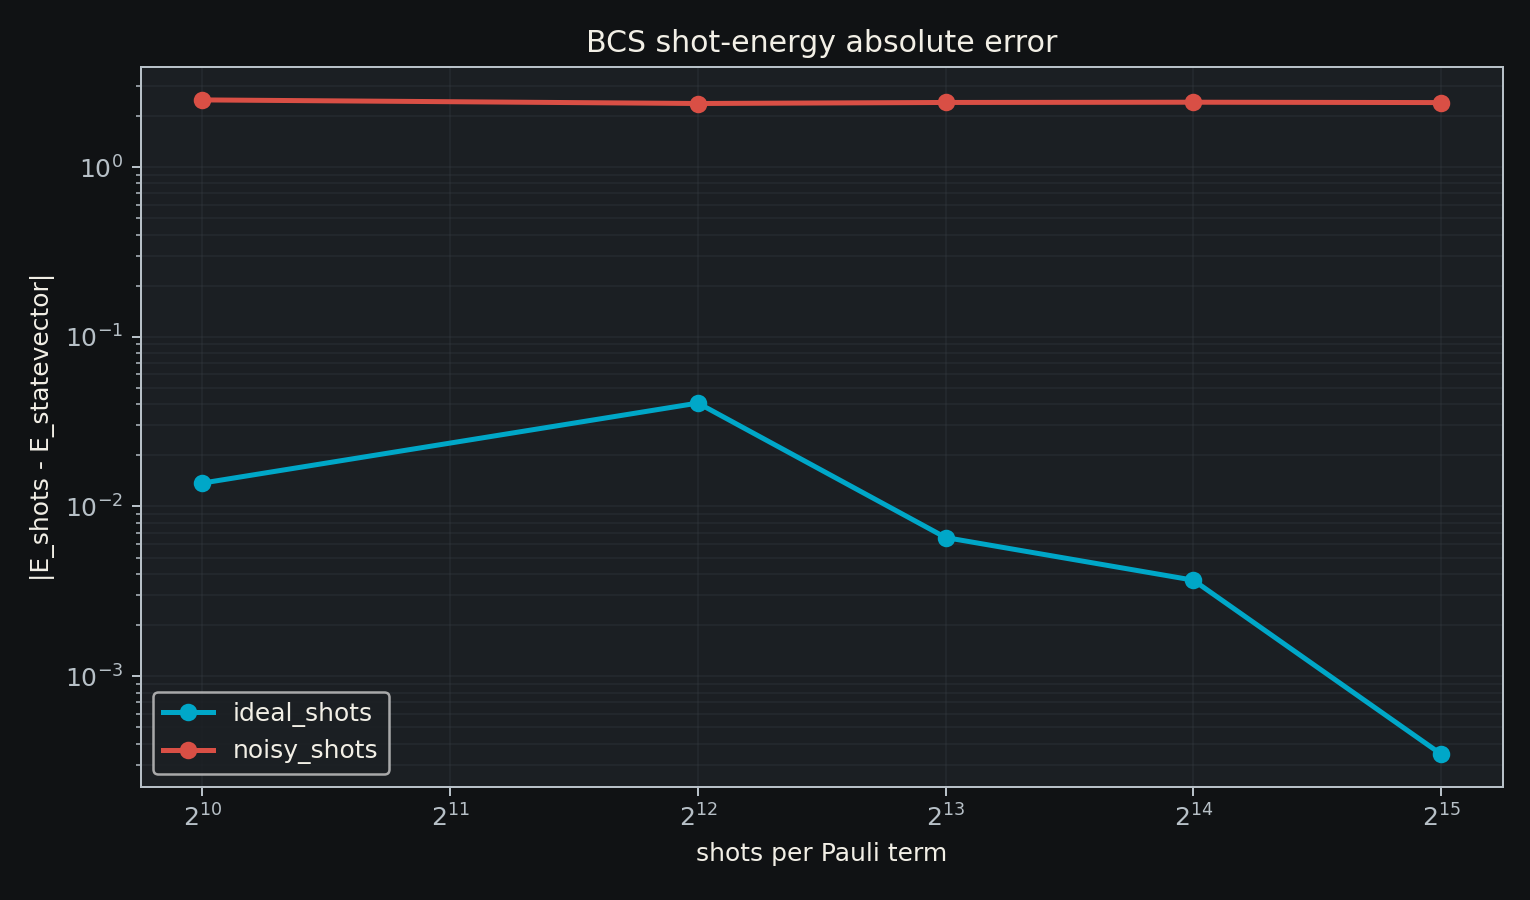

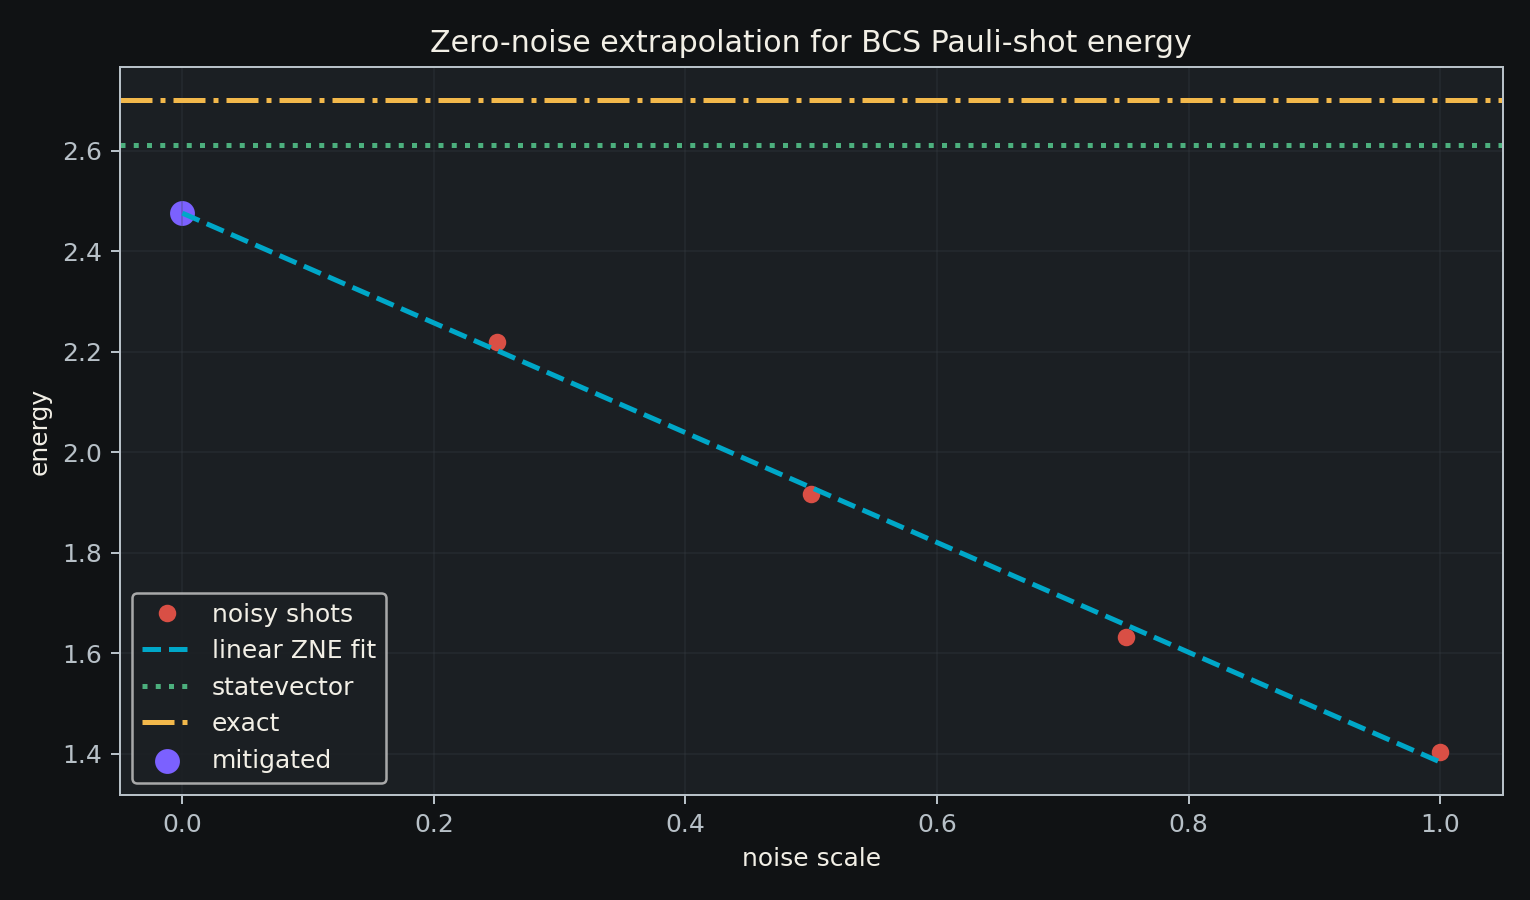

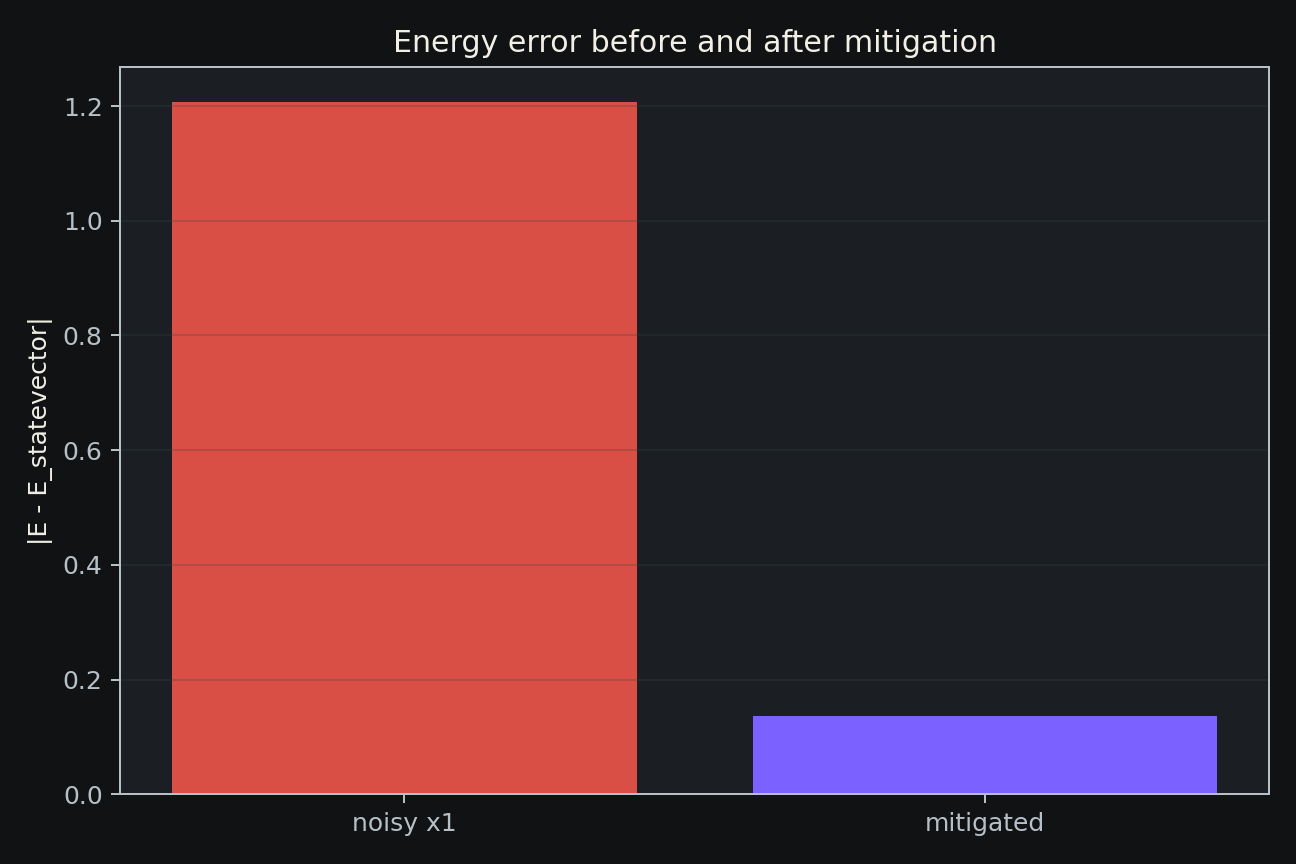

In [11]:
for fig in [
    'bcs_qiskit_shots_noise_total_pairs.png',
    'bcs_qiskit_shots_noise_occupations.png',
    'bcs_qiskit_energy_shots_values.png',
    'bcs_qiskit_energy_shots_error.png',
    'bcs_qiskit_error_mitigation_zne.png',
    'bcs_qiskit_error_mitigation_errors.png',
]:
    show_figure(fig, width=820)

## Resumo numérico final

In [12]:
energy_32768 = energy[(energy['mode'] == 'ideal_shots') & (energy['shots'] == 32768)].iloc[0]
noisy_scale_1 = mitigation[(mitigation['mode'] == 'scaled_noise') & (mitigation['noise_scale'] == 1.0)].iloc[0]
zne = mitigation[mitigation['mode'] == 'linear_zne'].iloc[0]

paper_summary = pd.DataFrame([
    {'metric': 'final observable fidelity', 'value': final_obs['fidelity']},
    {'metric': 'final state error', 'value': final_obs['state_error']},
    {'metric': 'normal Green peak omega', 'value': summary_spectral.loc[0, 'omega']},
    {'metric': 'anomalous Green peak omega', 'value': summary_spectral.loc[1, 'omega']},
    {'metric': 'Nambu trace peak omega', 'value': summary_spectral.loc[2, 'omega']},
    {'metric': '32768 ideal shot energy error vs statevector', 'value': energy_32768['abs_error_vs_statevector']},
    {'metric': 'noisy energy error before mitigation', 'value': noisy_scale_1['abs_error_vs_statevector']},
    {'metric': 'energy error after ZNE mitigation', 'value': zne['abs_error_vs_statevector']},
])
paper_summary

,metric,value
0,final observable fidelity,1.000000
1,final state error,0.001410
2,normal Green peak omega,-1.044297
3,anomalous Green peak omega,3.132890
4,Nambu trace peak omega,-2.436692
5,32768 ideal shot energy error vs statevector,0.000347
6,noisy energy error before mitigation,1.207430
7,energy error after ZNE mitigation,0.136205


## Regenerar resultados

Execute no terminal, a partir da raiz do repositório:

```bash
source .venv/bin/activate
python experiments/run_all.py
pandoc papers/bcs_quantum_simulation.md -s -o papers/bcs_quantum_simulation.html
google-chrome --headless --disable-gpu --no-sandbox \
  --print-to-pdf="$PWD/papers/bcs_quantum_simulation.pdf" \
  "file://$PWD/papers/bcs_quantum_simulation.html"
```

Para validar o núcleo:

```bash
PYTHONPATH=src .venv/bin/python -m pytest -q tests
```